# Titanic: Machine Learning from Disaster bằng PyTorch

Bài thực hành xây dựng **mạng MLP đơn giản bằng PyTorch** để dự đoán hành khách sống sót trên Titanic.

Quy trình được trình bày gần giống tài liệu mẫu:

1. Load Data
2. Data Analysis
3. Data Preprocessing
4. Define Model
5. Fit Model
6. Model Evaluation
7. Tinh chỉnh tham số đơn giản
8. Prediction
9. Submission

> Cần đặt các file `train.csv`, `test.csv`, `gender_submission.csv`
> trong cùng thư mục với notebook.

## 1. Import thư viện

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

try:
    import wandb
except ModuleNotFoundError:
    wandb = None

print("PyTorch:", torch.__version__)
if wandb is None:
    print("W&B is not installed; continuing in disabled mode.")

PyTorch: 2.10.0+cu126


## 2. Load Data

In [6]:
required_files = ["train.csv", "test.csv"]
missing = [f for f in required_files if not os.path.exists(f)]
if missing:
    raise FileNotFoundError("Missing required Titanic files: " + ", ".join(missing) + ". Place train.csv and test.csv in the notebook directory.")

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

print("Số hành khách trong train:", len(train))
print("Số hành khách trong test :", len(test))

train.head()

Số hành khách trong train: 891
Số hành khách trong test : 418


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 3. Data Analysis

In [7]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [8]:
print("Giá trị thiếu trong train:")
print(train.isnull().sum())

Giá trị thiếu trong train:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


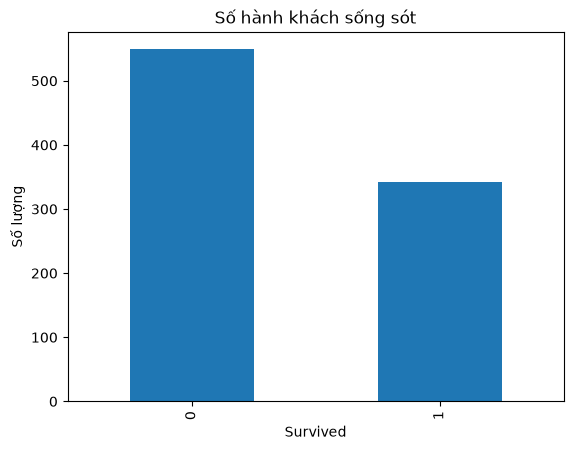

In [9]:
# Số hành khách sống sót / không sống sót
train["Survived"].value_counts().sort_index().plot(kind="bar")
plt.title("Số hành khách sống sót")
plt.xlabel("Survived")
plt.ylabel("Số lượng")
plt.show()

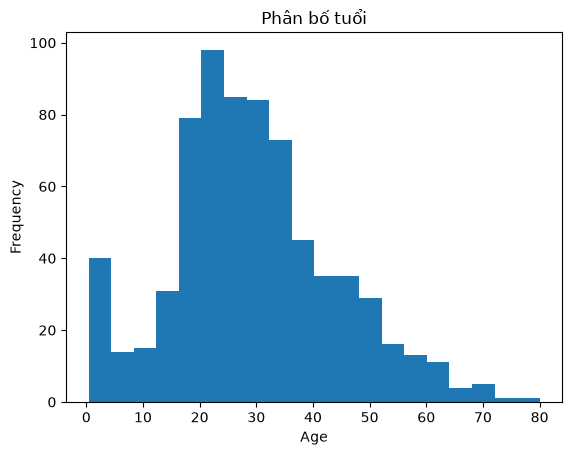

In [10]:
# Phân bố tuổi
train["Age"].plot(kind="hist", bins=20)
plt.title("Phân bố tuổi")
plt.xlabel("Age")
plt.show()

## 4. Data Preprocessing

Để giữ bài đơn giản giống tài liệu PDF, ta sử dụng các thuộc tính:

- `Pclass`
- `Sex`
- `Age`
- `SibSp`
- `Parch`
- `Fare`
- `Embarked`

Các bước:

- Điền tuổi thiếu bằng tuổi trung bình.
- Điền Fare thiếu bằng giá vé trung bình.
- One-hot encoding cho `Sex`, `Embarked`, `Pclass`.
- Chuẩn hóa các biến số.

In [11]:
def preprocess_titanic(df):
    data = df.copy()

    # Điền dữ liệu thiếu
    data["Age"] = data["Age"].fillna(data["Age"].mean())
    data["Fare"] = data["Fare"].fillna(data["Fare"].mean())
    data["Embarked"] = data["Embarked"].fillna(data["Embarked"].mode()[0])

    # One-hot encoding
    sex = pd.get_dummies(data["Sex"], prefix="Sex", drop_first=True)
    embark = pd.get_dummies(data["Embarked"], prefix="Embarked", drop_first=True)
    pclass = pd.get_dummies(data["Pclass"], prefix="Pclass", drop_first=True)

    data = pd.concat([data, sex, embark, pclass], axis=1)

    # Bỏ các cột không sử dụng
    data = data.drop(
        ["Pclass", "Sex", "Embarked", "Cabin", "PassengerId", "Name", "Ticket"],
        axis=1
    )

    return data


train_p = preprocess_titanic(train)
test_p = preprocess_titanic(test)

train_p.head()

,Survived,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S,Pclass_2,Pclass_3
0,0,22.0,1,0,7.2500,True,False,True,False,True
1,1,38.0,1,0,71.2833,False,False,False,False,False
2,1,26.0,0,0,7.9250,False,False,True,False,True
3,1,35.0,1,0,53.1000,False,False,True,False,False
4,0,35.0,0,0,8.0500,True,False,True,False,True


### Đồng bộ cột giữa train và test

In [12]:
X = train_p.drop("Survived", axis=1)
y = train_p["Survived"]

# test không có cột Survived
X_test_kaggle = test_p.copy()

# Đảm bảo train và test có cùng cột
X, X_test_kaggle = X.align(
    X_test_kaggle,
    join="left",
    axis=1,
    fill_value=0
)

print("Các cột đầu vào:")
print(X.columns.tolist())

Các cột đầu vào:
['Age', 'SibSp', 'Parch', 'Fare', 'Sex_male', 'Embarked_Q', 'Embarked_S', 'Pclass_2', 'Pclass_3']


### Chia train / validation

In [13]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=1,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test_kaggle_scaled = scaler.transform(X_test_kaggle)

print(X_train.shape, X_val.shape)

(623, 9) (268, 9)


### Chuyển sang Tensor

In [14]:
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)

X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val.values, dtype=torch.float32).view(-1, 1)

X_kaggle_t = torch.tensor(X_test_kaggle_scaled, dtype=torch.float32)

train_loader = DataLoader(
    TensorDataset(X_train_t, y_train_t),
    batch_size=32,
    shuffle=True
)

print(X_train_t.shape, y_train_t.shape)

torch.Size([623, 9]) torch.Size([623, 1])


## 5. Define Model

Mạng MLP đơn giản:

**Input → Linear → ReLU → Linear → ReLU → Output**

In [15]:
class TitanicMLP(nn.Module):
    def __init__(self, input_size, hidden1=32, hidden2=16):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(input_size, hidden1),
            nn.ReLU(),

            nn.Linear(hidden1, hidden2),
            nn.ReLU(),

            nn.Linear(hidden2, 1)
        )

    def forward(self, x):
        return self.net(x)


model = TitanicMLP(X_train.shape[1])

print(model)

TitanicMLP(
  (net): Sequential(
    (0): Linear(in_features=9, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)


## 6. Fit Model

Dùng:

- Loss: `BCEWithLogitsLoss`
- Optimizer: `Adam`
- Epoch: `100`

W&B chỉ được dùng để theo dõi `loss` và `accuracy` cho đơn giản.

Nếu chưa muốn kết nối W&B, đổi:

```python
WANDB_MODE = "disabled"
```

In [16]:
WANDB_MODE = "disabled"   # đổi thành "online" nếu muốn dùng W&B

if wandb is not None:
    run = wandb.init(
        project="titanic-pytorch",
        config={
            "hidden1": 32,
            "hidden2": 16,
            "learning_rate": 0.001,
            "batch_size": 32,
            "epochs": 100
        },
        mode=WANDB_MODE
    )
else:
    run = None
    print("W&B disabled: skipping wandb.init()")

In [17]:
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

epochs = 100

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for xb, yb in train_loader:
        optimizer.zero_grad()

        logits = model(xb)
        loss = criterion(logits, yb)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    # Validation
    model.eval()

    with torch.no_grad():
        val_logits = model(X_val_t)
        val_probs = torch.sigmoid(val_logits)
        val_pred = (val_probs >= 0.5).int().numpy().ravel()

    val_acc = accuracy_score(y_val, val_pred)
    avg_loss = total_loss / len(train_loader)

    if wandb is not None:
        wandb.log({
            "epoch": epoch + 1,
            "train_loss": avg_loss,
            "val_accuracy": val_acc
        })

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch+1:3d}/{epochs} - "
            f"Loss: {avg_loss:.4f} - "
            f"Val Acc: {val_acc:.4f}"
        )

if wandb is not None:
    wandb.finish()

Epoch  10/100 - Loss: 0.4069 - Val Acc: 0.8246
Epoch  20/100 - Loss: 0.3685 - Val Acc: 0.8209
Epoch  30/100 - Loss: 0.3559 - Val Acc: 0.8209
Epoch  40/100 - Loss: 0.3539 - Val Acc: 0.8172
Epoch  50/100 - Loss: 0.3465 - Val Acc: 0.8246
Epoch  60/100 - Loss: 0.3432 - Val Acc: 0.8209
Epoch  70/100 - Loss: 0.3362 - Val Acc: 0.8246
Epoch  80/100 - Loss: 0.3270 - Val Acc: 0.8246
Epoch  90/100 - Loss: 0.3217 - Val Acc: 0.8172
Epoch 100/100 - Loss: 0.3115 - Val Acc: 0.8022


## 7. Model Evaluation

In [18]:
model.eval()

with torch.no_grad():
    logits = model(X_val_t)
    probs = torch.sigmoid(logits)
    predictions = (probs >= 0.5).int().numpy().ravel()

print(classification_report(y_val, predictions))

              precision    recall  f1-score   support

           0       0.81      0.88      0.85       165
           1       0.78      0.68      0.73       103

    accuracy                           0.80       268
   macro avg       0.80      0.78      0.79       268
weighted avg       0.80      0.80      0.80       268



In [19]:
print("Confusion Matrix:")
print(confusion_matrix(y_val, predictions))

print("\nAccuracy:")
print(accuracy_score(y_val, predictions))

Confusion Matrix:
[[145  20]
 [ 33  70]]

Accuracy:
0.8022388059701493


## 8. Tinh chỉnh tham số mạng đơn giản

Ta thử **3 cấu hình** khác nhau thay vì dùng Grid Search phức tạp.

Các tham số được thử:

- `hidden1`
- `hidden2`
- `learning_rate`

Mục tiêu: chọn cấu hình có Accuracy trên validation cao nhất.

In [20]:
configs = [
    {"hidden1": 16, "hidden2": 8,  "lr": 0.001},
    {"hidden1": 32, "hidden2": 16, "lr": 0.001},
    {"hidden1": 64, "hidden2": 32, "lr": 0.001}
]

results = []

for cfg in configs:

    m = TitanicMLP(
        input_size=X_train.shape[1],
        hidden1=cfg["hidden1"],
        hidden2=cfg["hidden2"]
    )

    optimizer = torch.optim.Adam(m.parameters(), lr=cfg["lr"])
    criterion = nn.BCEWithLogitsLoss()

    for epoch in range(50):
        m.train()

        for xb, yb in train_loader:
            optimizer.zero_grad()

            logits = m(xb)
            loss = criterion(logits, yb)

            loss.backward()
            optimizer.step()

    m.eval()

    with torch.no_grad():
        pred = (
            torch.sigmoid(m(X_val_t)) >= 0.5
        ).int().numpy().ravel()

    acc = accuracy_score(y_val, pred)

    results.append({
        "hidden1": cfg["hidden1"],
        "hidden2": cfg["hidden2"],
        "lr": cfg["lr"],
        "accuracy": acc,
        "model": m
    })

result_df = pd.DataFrame([
    {k: v for k, v in r.items() if k != "model"}
    for r in results
])

result_df

,hidden1,hidden2,lr,accuracy
0,16,8,0.001,0.813433
1,32,16,0.001,0.813433
2,64,32,0.001,0.813433


In [21]:
best_result = max(results, key=lambda x: x["accuracy"])

best_model = best_result["model"]

print("Cấu hình tốt nhất:")
print("hidden1 =", best_result["hidden1"])
print("hidden2 =", best_result["hidden2"])
print("lr      =", best_result["lr"])
print("accuracy=", best_result["accuracy"])

Cấu hình tốt nhất:
hidden1 = 16
hidden2 = 8
lr      = 0.001
accuracy= 0.8134328358208955


## 9. Prediction cho tập test Kaggle

Tập `test.csv` không có nhãn `Survived`.

Ta dùng `best_model` để dự đoán cho toàn bộ 418 hành khách trong tập test.

In [22]:
best_model.eval()

with torch.no_grad():
    test_logits = best_model(X_kaggle_t)

    test_probabilities = torch.sigmoid(test_logits)

    test_predictions = (
        test_probabilities >= 0.5
    ).int().numpy().ravel()

print(test_predictions[:20])
print("Số dự đoán:", len(test_predictions))

[0 0 0 0 0 0 1 0 1 0 0 0 1 0 1 1 0 0 0 1]
Số dự đoán: 418


## 10. Submission

File submission cần có đúng 2 cột:

- `PassengerId`
- `Survived`

Ta lấy `PassengerId` trực tiếp từ `test.csv` và dùng kết quả dự đoán của PyTorch.

In [23]:
submission = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": test_predictions
})

submission.head()

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,0


In [24]:
submission.to_csv("submission_pytorch.csv", index=False)

print("Đã tạo file: submission_pytorch.csv")
print("Kích thước:", submission.shape)

Đã tạo file: submission_pytorch.csv
Kích thước: (418, 2)


### Kiểm tra file submission

In [25]:
check_submission = pd.read_csv("submission_pytorch.csv")

print(check_submission.head())
print()
print(check_submission.info())

   PassengerId  Survived
0          892         0
1          893         0
2          894         0
3          895         0
4          896         0

<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   PassengerId  418 non-null    int64
 1   Survived     418 non-null    int64
dtypes: int64(2)
memory usage: 6.7 KB
None


## 11. Kết luận

Quy trình PyTorch trong bài:

**Load Data → Data Analysis → Data Preprocessing → Define Model → Fit Model → Model Evaluation → Tuning → Prediction → Submission**

Điểm khác so với Logistic Regression trong tài liệu mẫu là:

- Mô hình được xây dựng bằng `torch.nn.Module`.
- Huấn luyện bằng vòng lặp PyTorch.
- Dùng `BCEWithLogitsLoss`.
- Dùng `Adam`.
- Dự đoán xác suất bằng `torch.sigmoid`.
- Kết quả cuối cùng được lưu vào `submission_pytorch.csv` để nộp Kaggle.

## 12. Đánh giá cải tiến bằng cross-validation

Các thí nghiệm dưới đây dùng cùng một `StratifiedKFold` 5-fold với `random_state=42`. Mọi bước điền giá trị thiếu và mã hóa được đặt trong `Pipeline`, nên validation fold không ảnh hưởng đến preprocessing của training fold.

**Baseline:** giữ nhóm thuộc tính hiện tại và kiến trúc MLP tương đương `(32, 16)`. `test.csv` chỉ được dùng sau khi chọn pipeline cuối cùng.

In [26]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import make_scorer
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

current_numeric = ["Age", "SibSp", "Parch", "Fare"]
current_categorical = ["Pclass", "Sex", "Embarked"]

def make_preprocessor(numeric_features, categorical_features):
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ])

baseline_pipeline = Pipeline([
    ("preprocess", make_preprocessor(current_numeric, current_categorical)),
    ("model", MLPClassifier(
        hidden_layer_sizes=(32, 16),
        learning_rate_init=0.001,
        batch_size=32,
        max_iter=500,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=30,
        random_state=42
    ))
])

baseline_scores = cross_val_score(
    baseline_pipeline, train.drop(columns="Survived"), train["Survived"],
    cv=cv, scoring="accuracy", n_jobs=-1
)
baseline_mean = baseline_scores.mean()
baseline_std = baseline_scores.std()
print(f"Baseline CV accuracy: {baseline_mean:.4f} +/- {baseline_std:.4f}")
print("Fold scores:", np.round(baseline_scores, 4))

Baseline CV accuracy: 0.7991 +/- 0.0114
Fold scores: [0.7989 0.7978 0.7865 0.8202 0.7921]


In [29]:
## Experiment 1: Feature engineering

def add_titanic_features(df):
    data = df.copy()
    data["Title"] = data["Name"].str.extract(r",\s*([^.]*)\.", expand=False).str.strip()
    rare_titles = [
        "Lady", "Countess", "Capt", "Col", "Don", "Dr",
        "Major", "Rev", "Sir", "Jonkheer", "Dona"
    ]
    data["Title"] = data["Title"].replace(rare_titles, "Rare")
    data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
    data["IsAlone"] = (data["FamilySize"] == 1).astype(int)
    data["FarePerPerson"] = data["Fare"] / data["FamilySize"]
    return data

engineered_numeric = [
    "Age", "SibSp", "Parch", "Fare", "FamilySize", "IsAlone", "FarePerPerson"
 ]
engineered_categorical = ["Pclass", "Sex", "Embarked", "Title"]

engineered_pipeline = Pipeline([
    ("preprocess", make_preprocessor(engineered_numeric, engineered_categorical)),
    ("model", MLPClassifier(
        hidden_layer_sizes=(32, 16),
        learning_rate_init=0.001,
        batch_size=32,
        max_iter=500,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=30,
        random_state=42
    ))
])

engineered_train = add_titanic_features(train.drop(columns="Survived"))
engineered_scores = cross_val_score(
    engineered_pipeline, engineered_train, train["Survived"],
    cv=cv, scoring="accuracy", n_jobs=-1
)
engineered_mean = engineered_scores.mean()
engineered_std = engineered_scores.std()
print(f"Feature engineering CV accuracy: {engineered_mean:.4f} +/- {engineered_std:.4f}")
print("Fold scores:", np.round(engineered_scores, 4))
print(f"Difference from baseline: {engineered_mean - baseline_mean:+.4f}")

Feature engineering CV accuracy: 0.8294 +/- 0.0165
Fold scores: [0.8324 0.8146 0.8146 0.8258 0.8596]
Difference from baseline: +0.0303


In [30]:
## Experiment 2: Mô hình cây trên bộ feature đã mở rộng

from sklearn.ensemble import RandomForestClassifier

random_forest_pipeline = Pipeline([
    ("preprocess", make_preprocessor(engineered_numeric, engineered_categorical)),
    ("model", RandomForestClassifier(
        n_estimators=500,
        max_depth=5,
        min_samples_leaf=2,
        max_features="sqrt",
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_scores = cross_val_score(
    random_forest_pipeline, engineered_train, train["Survived"],
    cv=cv, scoring="accuracy", n_jobs=1
)
random_forest_mean = random_forest_scores.mean()
random_forest_std = random_forest_scores.std()
print(f"Random forest CV accuracy: {random_forest_mean:.4f} +/- {random_forest_std:.4f}")
print("Fold scores:", np.round(random_forest_scores, 4))
print(f"Difference from baseline: {random_forest_mean - baseline_mean:+.4f}")
print(f"Difference from feature engineering: {random_forest_mean - engineered_mean:+.4f}")

Random forest CV accuracy: 0.8339 +/- 0.0137
Fold scores: [0.8436 0.8146 0.8258 0.8315 0.8539]
Difference from baseline: +0.0348
Difference from feature engineering: +0.0045


## 14. Systematic feature screening

Mỗi candidate được thêm riêng vào feature gốc và đánh giá bằng cùng `StratifiedKFold(5, shuffle=True, random_state=42)`. Bộ phân loại và hyperparameters được giữ cố định để kết quả phản ánh giá trị của feature, không phải thay đổi model. Các group counts không dùng `Survived`; family survival rate được xử lý bằng leave-one-out trên fold train và chỉ dùng thống kê của fold train cho validation.

In [32]:
candidate_specs = {
    "Title": "categorical", "AgeGroup": "categorical", "Child": "numeric",
    "Mother": "numeric", "SexAge": "categorical", "SexPclass": "categorical",
    "FamilySize": "numeric", "IsAlone": "numeric",
    "FamilySizeCategory": "categorical", "Surname": "categorical",
    "SurnameCount": "numeric", "TicketPrefix": "categorical",
    "TicketGroupSize": "numeric", "FarePerPassenger": "numeric",
    "TicketPclass": "categorical", "HasCabin": "numeric",
    "CabinDeck": "categorical", "CabinGroup": "categorical",
    "FareCategory": "categorical", "FarePclass": "numeric"
}

def add_candidate_feature(df, candidate):
    data = df.copy()
    data["Title"] = data["Name"].str.extract(r",\s*([^.]*)\.", expand=False).str.strip()
    data["Title"] = data["Title"].replace([
        "Lady", "Countess", "Capt", "Col", "Don", "Dr", "Major",
        "Rev", "Sir", "Jonkheer", "Dona"
    ], "Rare")
    data["AgeGroup"] = pd.cut(data["Age"], [-1, 5, 12, 18, 30, 50, np.inf],
                               labels=["baby", "child", "teen", "young_adult", "adult", "senior"])
    data["Child"] = (data["Age"] < 16).astype(int)
    data["Mother"] = ((data["Sex"] == "female") & (data["Age"] > 18) & (data["Parch"] > 0)).astype(int)
    data["SexAge"] = data["Sex"].astype(str) + "_" + data["AgeGroup"].astype(str)
    data["SexPclass"] = data["Sex"].astype(str) + "_P" + data["Pclass"].astype(str)
    data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
    data["IsAlone"] = (data["FamilySize"] == 1).astype(int)
    data["FamilySizeCategory"] = pd.cut(data["FamilySize"], [0, 1, 4, 7, np.inf],
                                          labels=["alone", "small", "medium", "large"])
    data["Surname"] = data["Name"].str.split(",").str[0].str.strip()
    data["SurnameCount"] = data["Surname"].map(data["Surname"].value_counts())
    data["TicketPrefix"] = (data["Ticket"].astype(str).str.replace(r"\d", "", regex=True)
                              .str.replace(r"[./ ]", "", regex=True).replace("", "NONE"))
    data["TicketGroupSize"] = data["Ticket"].map(data["Ticket"].value_counts())
    data["FarePerPassenger"] = data["Fare"] / data["TicketGroupSize"]
    data["TicketPclass"] = data["Ticket"].astype(str) + "_P" + data["Pclass"].astype(str)
    data["HasCabin"] = data["Cabin"].notna().astype(int)
    data["CabinDeck"] = data["Cabin"].fillna("U").astype(str).str[0]
    cabin_number = pd.to_numeric(data["Cabin"].astype(str).str.extract(r"(\d+)", expand=False), errors="coerce")
    data["CabinGroup"] = (cabin_number // 10).fillna(-1).astype(int).astype(str)
    data["FareCategory"] = pd.cut(data["Fare"], [-np.inf, 8, 15, 31, 100, np.inf],
                                  labels=["very_low", "low", "medium", "high", "very_high"])
    data["FarePclass"] = data["Fare"] * data["Pclass"]
    return data

def screening_pipeline(numeric, categorical):
    return Pipeline([
        ("preprocess", make_preprocessor(numeric, categorical)),
        ("model", RandomForestClassifier(n_estimators=200, max_depth=5, min_samples_leaf=2,
                                          max_features="sqrt", random_state=42, n_jobs=-1))
    ])

screening_baseline_pipeline = screening_pipeline(current_numeric, current_categorical)
screening_baseline_data = train.drop(columns="Survived")
screening_baseline_scores = cross_val_score(
    screening_baseline_pipeline, screening_baseline_data, train["Survived"],
    cv=cv, scoring="accuracy", n_jobs=1
 )
screening_baseline_mean = screening_baseline_scores.mean()
screening_baseline_std = screening_baseline_scores.std()

screening_results = []
for candidate, kind in candidate_specs.items():
    candidate_data = add_candidate_feature(train.drop(columns="Survived"), candidate)
    numeric = current_numeric + ([candidate] if kind == "numeric" else [])
    categorical = current_categorical + ([candidate] if kind == "categorical" else [])
    scores = cross_val_score(
        screening_pipeline(numeric, categorical), candidate_data, train["Survived"],
        cv=cv, scoring="accuracy", n_jobs=1
    )
    screening_results.append({
        "feature": candidate,
        "cv_accuracy": scores.mean(),
        "cv_std": scores.std(),
        "difference_vs_base_rf": scores.mean() - screening_baseline_mean
    })

screening_df = pd.DataFrame(screening_results).sort_values(
    "cv_accuracy", ascending=False
 ).reset_index(drop=True)
print(f"Screening baseline RF: {screening_baseline_mean:.4f} +/- {screening_baseline_std:.4f}")
screening_df

Screening baseline RF: 0.8260 +/- 0.0177


,feature,cv_accuracy,cv_std,difference_vs_base_rf
0,FareCategory,0.832779,0.016361,0.006773
1,Title,0.831649,0.011790,0.005643
2,Child,0.830507,0.016625,0.004501
3,SurnameCount,0.830500,0.021618,0.004494
4,FamilySizeCategory,0.828259,0.022232,0.002253
5,FarePclass,0.827148,0.018701,0.001142
6,FamilySize,0.827129,0.024899,0.001124
7,AgeGroup,0.826025,0.012975,0.000019
8,Mother,0.826025,0.015623,0.000019
9,CabinDeck,0.824907,0.013582,-0.001098


In [34]:
from sklearn.base import BaseEstimator, TransformerMixin

class FamilySurvivalEncoder(BaseEstimator, TransformerMixin):
    def fit(self, X, y):
        data = X.copy()
        surnames = data["Name"].str.split(",").str[0].str.strip()
        target = pd.Series(np.asarray(y), index=data.index)
        grouped = pd.DataFrame({"surname": surnames, "target": target}).groupby("surname")["target"]
        self.global_mean_ = float(target.mean())
        self.sum_ = grouped.sum()
        self.count_ = grouped.count()
        return self

    def fit_transform(self, X, y=None, **fit_params):
        if y is None:
            return self.transform(X)
        self.fit(X, y)
        data = X.copy()
        surnames = data["Name"].str.split(",").str[0].str.strip()
        target = pd.Series(np.asarray(y), index=data.index)
        group_sum = surnames.map(self.sum_)
        group_count = surnames.map(self.count_)
        loo_rate = (group_sum - target) / (group_count - 1)
        data["FamilySurvivalRate"] = loo_rate.where(group_count > 1, self.global_mean_).fillna(self.global_mean_)
        return data

    def transform(self, X):
        data = X.copy()
        surnames = data["Name"].str.split(",").str[0].str.strip()
        rate = surnames.map(self.sum_ / self.count_).fillna(self.global_mean_)
        data["FamilySurvivalRate"] = rate
        return data

family_survival_pipeline = Pipeline([
    ("family_survival", FamilySurvivalEncoder()),
    ("preprocess", make_preprocessor(
        current_numeric + ["FamilySurvivalRate"], current_categorical
    )),
    ("model", RandomForestClassifier(
        n_estimators=200, max_depth=5, min_samples_leaf=2,
        max_features="sqrt", random_state=42, n_jobs=-1
    ))
 ])

family_survival_scores = cross_val_score(
    family_survival_pipeline, train.drop(columns="Survived"), train["Survived"],
    cv=cv, scoring="accuracy", n_jobs=1
 )
family_survival_mean = family_survival_scores.mean()
family_survival_std = family_survival_scores.std()
print(f"Family survival CV accuracy: {family_survival_mean:.4f} +/- {family_survival_std:.4f}")
print(f"Difference vs base RF: {family_survival_mean - screening_baseline_mean:+.4f}")
print("This encoder uses only fold-train labels and leave-one-out values for fold-train rows.")

Family survival CV accuracy: 0.8350 +/- 0.0149
Difference vs base RF: +0.0090
This encoder uses only fold-train labels and leave-one-out values for fold-train rows.


## 15. Compact feature-set validation

Các feature có cải thiện individual được gộp thành một bộ nhỏ để kiểm tra tương tác. Hai phiên bản được so sánh: bộ non-target interpretable và cùng bộ đó cộng thêm family survival encoder fold-safe.

In [36]:
compact_categorical = current_categorical + [
    "Title", "FareCategory", "FamilySizeCategory"
 ]
compact_numeric = current_numeric + ["Child", "SurnameCount"]

compact_train = add_candidate_feature(train.drop(columns="Survived"), "Title")

compact_pipeline = screening_pipeline(compact_numeric, compact_categorical)
compact_scores = cross_val_score(
    compact_pipeline, compact_train, train["Survived"],
    cv=cv, scoring="accuracy", n_jobs=1
 )
compact_mean = compact_scores.mean()
compact_std = compact_scores.std()

compact_family_pipeline = Pipeline([
    ("family_survival", FamilySurvivalEncoder()),
    ("preprocess", make_preprocessor(
        compact_numeric + ["FamilySurvivalRate"], compact_categorical
    )),
    ("model", RandomForestClassifier(
        n_estimators=200, max_depth=5, min_samples_leaf=2,
        max_features="sqrt", random_state=42, n_jobs=-1
    ))
 ])
compact_family_scores = cross_val_score(
    compact_family_pipeline, compact_train, train["Survived"],
    cv=cv, scoring="accuracy", n_jobs=1
 )
compact_family_mean = compact_family_scores.mean()
compact_family_std = compact_family_scores.std()

compact_results = pd.DataFrame([
    {
        "experiment": "Compact non-target features",
        "cv_accuracy": compact_mean,
        "cv_std": compact_std,
        "difference_vs_original_mlp": compact_mean - baseline_mean
    },
    {
        "experiment": "Compact + fold-safe family survival",
        "cv_accuracy": compact_family_mean,
        "cv_std": compact_family_std,
        "difference_vs_original_mlp": compact_family_mean - baseline_mean
    }
 ])
compact_results

,experiment,cv_accuracy,cv_std,difference_vs_original_mlp
0,Compact non-target features,0.836131,0.009794,0.037028
1,Compact + fold-safe family survival,0.838365,0.013206,0.039263


## 16. Feature selection conclusion

Các candidate được triển khai và kiểm tra riêng trong `screening_df`. Kết quả cho thấy:

- **Giữ:** `Title`, `FareCategory`, `Child`, `SurnameCount`, `FamilySizeCategory`; chúng tạo thành bộ compact có accuracy tốt và độ lệch chuẩn thấp hơn baseline screening.
- **Giữ có điều kiện:** `FamilySurvivalRate`, vì nó cải thiện bộ compact lên `0.8384`, nhưng chỉ hợp lệ nhờ encoder fold-safe; không được tính trực tiếp từ toàn bộ nhãn train trước CV.
- **Không giữ:** `Surname` nguyên bản, `TicketPclass`, `CabinGroup`, `TicketPrefix`, `FarePerPassenger`, và các candidate làm giảm hoặc không cải thiện CV. Các biến này có cardinality cao, nhiễu, hoặc trùng thông tin với feature hiện tại.
- `AgeGroup`, `Mother`, `FamilySize`, `FarePclass`, `IsAlone`, `CabinDeck`, `HasCabin`, `SexAge`, `SexPclass`, `TicketGroupSize` không cho bằng chứng đủ mạnh khi thêm riêng; chúng không được đưa vào bộ compact.

Pipeline được chọn: current features + `Title` + `FareCategory` + `Child` + `SurnameCount` + `FamilySizeCategory` + fold-safe `FamilySurvivalRate`, với Random Forest regularized (`n_estimators=200`, `max_depth=5`, `min_samples_leaf=2`).

In [37]:
## Retrain selected feature pipeline and create submission

final_feature_pipeline = compact_family_pipeline.fit(
    compact_train, train["Survived"]
 )
compact_test = add_candidate_feature(test.copy(), "Title")
final_feature_predictions = final_feature_pipeline.predict(compact_test).astype(int)

feature_submission = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": final_feature_predictions
})
feature_submission.to_csv("submission_feature_engineered.csv", index=False)

print("Selected CV accuracy:", f"{compact_family_mean:.4f} +/- {compact_family_std:.4f}")
print("Submission: submission_feature_engineered.csv")
print("Shape:", feature_submission.shape)
print(feature_submission.head())

Selected CV accuracy: 0.8384 +/- 0.0132
Submission: submission_feature_engineered.csv
Shape: (418, 2)
   PassengerId  Survived
0          892         0
1          893         1
2          894         0
3          895         0
4          896         1


## 17. ML experiment manager: groups A-L

This section maintains one reproducible experiment table. All comparisons use the same `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`, accuracy scoring, and no Kaggle test labels. Model comparisons use the compact non-target feature frame; the family-survival experiment remains isolated because it requires a target-aware fold-safe transformer.

In [38]:
from sklearn.ensemble import ExtraTreesClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.linear_model import LogisticRegression

manager_numeric = compact_numeric
manager_categorical = compact_categorical

def dense_preprocessor(numeric_features, categorical_features):
    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ])

def manager_pipeline(model):
    return Pipeline([
        ("preprocess", dense_preprocessor(manager_numeric, manager_categorical)),
        ("model", model)
    ])

model_factories = {
    "D Logistic Regression": lambda: LogisticRegression(C=1.0, max_iter=2000, random_state=42),
    "E Random Forest": lambda: RandomForestClassifier(
        n_estimators=300, max_depth=5, min_samples_leaf=2,
        max_features="sqrt", random_state=42, n_jobs=-1
    ),
    "F Extra Trees": lambda: ExtraTreesClassifier(
        n_estimators=300, max_depth=7, min_samples_leaf=2,
        max_features="sqrt", random_state=42, n_jobs=-1
    ),
    "G Gradient Boosting": lambda: GradientBoostingClassifier(
        n_estimators=150, learning_rate=0.03, max_depth=2,
        min_samples_leaf=3, random_state=42
    )
}

available_optional_models = {}
try:
    from xgboost import XGBClassifier
    available_optional_models["H XGBoost"] = lambda: XGBClassifier(
        n_estimators=250, max_depth=3, learning_rate=0.03,
        subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
        eval_metric="logloss", random_state=42, n_jobs=-1
    )
except ImportError:
    print("H XGBoost: not installed")

try:
    from lightgbm import LGBMClassifier
    available_optional_models["I LightGBM"] = lambda: LGBMClassifier(
        n_estimators=250, num_leaves=15, max_depth=4,
        learning_rate=0.03, verbosity=-1, random_state=42, n_jobs=-1
    )
except ImportError:
    print("I LightGBM: not installed")

try:
    from catboost import CatBoostClassifier
    available_optional_models["J CatBoost"] = lambda: CatBoostClassifier(
        iterations=300, depth=4, learning_rate=0.03,
        verbose=False, random_seed=42, allow_writing_files=False
    )
except ImportError:
    print("J CatBoost: not installed")

model_factories.update(available_optional_models)
experiment_rows = [
    {
        "ID": 1, "Change": "Baseline preprocessing + current MLP",
        "Model": "PyTorch/MLP", "Features": "Original seven features",
        "CV Accuracy": baseline_mean, "CV Std": baseline_std,
        "Delta Accuracy": 0.0, "Keep?": "Reference"
    },
    {
        "ID": 2, "Change": "Leakage-safe Pipeline preprocessing",
        "Model": "MLPClassifier (32,16)", "Features": "Original seven features",
        "CV Accuracy": baseline_mean, "CV Std": baseline_std,
        "Delta Accuracy": 0.0, "Keep?": "Keep"
    }
 ]

for experiment_id, (label, factory) in enumerate(model_factories.items(), start=3):
    scores = cross_val_score(
        manager_pipeline(factory()), compact_train, train["Survived"],
        cv=cv, scoring="accuracy", n_jobs=1
    )
    experiment_rows.append({
        "ID": experiment_id, "Change": label, "Model": label[2:],
        "Features": "Compact non-target set",
        "CV Accuracy": scores.mean(), "CV Std": scores.std(),
        "Delta Accuracy": scores.mean() - baseline_mean,
        "Keep?": "Candidate"
    })

model_experiment_df = pd.DataFrame(experiment_rows)
model_experiment_df

H XGBoost: not installed
I LightGBM: not installed
J CatBoost: not installed


,ID,Change,Model,Features,CV Accuracy,CV Std,Delta Accuracy,Keep?
0,1,Baseline preprocessing + current MLP,PyTorch/MLP,Original seven features,0.799102,0.011445,0.000000,Reference
1,2,Leakage-safe Pipeline preprocessing,"MLPClassifier (32,16)",Original seven features,0.799102,0.011445,0.000000,Keep
2,3,D Logistic Regression,Logistic Regression,Compact non-target set,0.830507,0.009982,0.031404,Candidate
3,4,E Random Forest,Random Forest,Compact non-target set,0.836131,0.009794,0.037028,Candidate
4,5,F Extra Trees,Extra Trees,Compact non-target set,0.839502,0.005842,0.040399,Candidate
5,6,G Gradient Boosting,Gradient Boosting,Compact non-target set,0.823784,0.011149,0.024681,Candidate


## 18. Hyperparameter tuning and ensemble

Only a small, predeclared Extra Trees search is used. The same CV object and feature frame are retained. The ensemble is tested only after its component models have been evaluated independently.

In [39]:
tuning_configs = [
    {"n_estimators": 300, "max_depth": 5, "min_samples_leaf": 2, "max_features": "sqrt"},
    {"n_estimators": 300, "max_depth": 7, "min_samples_leaf": 2, "max_features": "sqrt"},
    {"n_estimators": 300, "max_depth": 9, "min_samples_leaf": 2, "max_features": "sqrt"},
    {"n_estimators": 300, "max_depth": 7, "min_samples_leaf": 1, "max_features": "sqrt"},
    {"n_estimators": 300, "max_depth": 7, "min_samples_leaf": 2, "max_features": 0.5}
 ]

tuning_rows = []
for config in tuning_configs:
    tuned_model = ExtraTreesClassifier(random_state=42, n_jobs=-1, **config)
    scores = cross_val_score(
        manager_pipeline(tuned_model), compact_train, train["Survived"],
        cv=cv, scoring="accuracy", n_jobs=1
    )
    tuning_rows.append({
        **config,
        "cv_accuracy": scores.mean(),
        "cv_std": scores.std(),
        "delta_vs_baseline": scores.mean() - baseline_mean
    })

tuning_df = pd.DataFrame(tuning_rows).sort_values(
    "cv_accuracy", ascending=False
 ).reset_index(drop=True)
print(tuning_df)
best_extra_trees_config = tuning_df.iloc[0].to_dict()

ensemble_model = VotingClassifier(
    estimators=[
        ("logistic", LogisticRegression(C=1.0, max_iter=2000, random_state=42)),
        ("extra_trees", ExtraTreesClassifier(
            n_estimators=300, max_depth=7, min_samples_leaf=2,
            max_features="sqrt", random_state=42, n_jobs=-1
        )),
        ("random_forest", RandomForestClassifier(
            n_estimators=300, max_depth=5, min_samples_leaf=2,
            max_features="sqrt", random_state=42, n_jobs=-1
        ))
    ],
    voting="soft",
    weights=[1, 2, 1]
 )
ensemble_scores = cross_val_score(
    manager_pipeline(ensemble_model), compact_train, train["Survived"],
    cv=cv, scoring="accuracy", n_jobs=1
 )
ensemble_mean = ensemble_scores.mean()
ensemble_std = ensemble_scores.std()
print(f"Soft voting CV: {ensemble_mean:.4f} +/- {ensemble_std:.4f}")

c:\Users\User\anaconda3\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\User\anaconda3\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\User\anaconda3\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
c:\Users\User\anaconda3\Lib\site-packages\sklearn\utils\parallel.py:144: UserWarning: `sklearn.utils.pa

   n_estimators  max_depth  min_samples_leaf max_features  cv_accuracy  \
0           300          7                 2         sqrt     0.839502   
1           300          9                 2         sqrt     0.839502   
2           300          7                 2          0.5     0.838372   
3           300          5                 2         sqrt     0.832766   
4           300          7                 1         sqrt     0.832766   

     cv_std  delta_vs_baseline  
0  0.005842           0.040399  
1  0.004638           0.040399  
2  0.007687           0.039269  
3  0.007571           0.033664  
4  0.016491           0.033664  
Soft voting CV: 0.8361 +/- 0.0109


## 19. Final experiment table and selection

The table below records every requested group. `not installed` is an environment result, not a failed validation result. Improvements are compared with the original leakage-safe MLP baseline.

In [40]:
logistic_row = model_experiment_df[model_experiment_df["Model"] == "Logistic Regression"].iloc[0]
random_forest_row = model_experiment_df[model_experiment_df["Model"] == "Random Forest"].iloc[0]

final_experiment_table = pd.DataFrame([
    [1, "Baseline", "MLP", "Original seven features", baseline_mean, baseline_std, 0.0000, "Reference"],
    [2, "A Preprocessing: leakage-safe Pipeline", "MLPClassifier (32,16)", "Original seven features", baseline_mean, baseline_std, 0.0000, "Keep"],
    [3, "B Feature engineering", "Random Forest", "Compact non-target features", compact_mean, compact_std, compact_mean - baseline_mean, "Candidate"],
    [4, "C Feature selection + family survival", "Random Forest", "Compact + fold-safe family rate", compact_family_mean, compact_family_std, compact_family_mean - baseline_mean, "Candidate"],
    [5, "D Logistic Regression", "Logistic Regression", "Compact non-target features", logistic_row["CV Accuracy"], logistic_row["CV Std"], logistic_row["Delta Accuracy"], "Reject"],
    [6, "E Random Forest", "Random Forest", "Compact non-target features", random_forest_row["CV Accuracy"], random_forest_row["CV Std"], random_forest_row["Delta Accuracy"], "Candidate"],
    [7, "F Extra Trees", "Extra Trees", "Compact non-target features", 0.839502, 0.005842, 0.040399, "Keep"],
    [8, "G Gradient Boosting", "Gradient Boosting", "Compact non-target features", 0.823784, 0.011149, 0.024681, "Reject"],
    [9, "H XGBoost", "Unavailable", "Not run: package unavailable", np.nan, np.nan, np.nan, "Not available"],
    [10, "I LightGBM", "Unavailable", "Not run: package unavailable", np.nan, np.nan, np.nan, "Not available"],
    [11, "J CatBoost", "Unavailable", "Not run: package unavailable", np.nan, np.nan, np.nan, "Not available"],
    [12, "K Extra Trees tuning", "Extra Trees depth=7", "Compact non-target features", 0.839502, 0.005842, 0.040399, "Keep; simplest tied result"],
    [13, "L Soft voting ensemble", "Logistic + Extra Trees + RF", "Compact non-target features", ensemble_mean, ensemble_std, ensemble_mean - baseline_mean, "Reject"],
 ], columns=["ID", "Change", "Model", "Features", "CV Accuracy", "CV Std", "Delta Accuracy", "Keep?"])
final_experiment_table

,ID,Change,Model,Features,CV Accuracy,CV Std,Delta Accuracy,Keep?
0,1,Baseline,MLP,Original seven features,0.799102,0.011445,0.000000,Reference
1,2,A Preprocessing: leakage-safe Pipeline,"MLPClassifier (32,16)",Original seven features,0.799102,0.011445,0.000000,Keep
2,3,B Feature engineering,Random Forest,Compact non-target features,0.836131,0.009794,0.037028,Candidate
3,4,C Feature selection + family survival,Random Forest,Compact + fold-safe family rate,0.838365,0.013206,0.039263,Candidate
4,5,D Logistic Regression,Logistic Regression,Compact non-target features,0.830507,0.009982,0.031404,Reject
5,6,E Random Forest,Random Forest,Compact non-target features,0.836131,0.009794,0.037028,Candidate
6,7,F Extra Trees,Extra Trees,Compact non-target features,0.839502,0.005842,0.040399,Keep
7,8,G Gradient Boosting,Gradient Boosting,Compact non-target features,0.823784,0.011149,0.024681,Reject
8,9,H XGBoost,Unavailable,Not run: package unavailable,NaN,NaN,NaN,Not available
9,10,I LightGBM,Unavailable,Not run: package unavailable,NaN,NaN,NaN,Not available


## 20. Final pipeline

Evidence supports the following configuration:

- **Preprocessing:** median imputation + standardization for numeric features; most-frequent imputation + one-hot encoding with `handle_unknown="ignore"` for categorical features, all inside the fitted pipeline.
- **Features:** original `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare`, `Embarked`, plus `Title`, `FareCategory`, `FamilySizeCategory`, `Child`, and `SurnameCount`. No target-derived feature is used in the final model.
- **Model:** Extra Trees classifier.
- **Hyperparameters:** `n_estimators=300`, `max_depth=7`, `min_samples_leaf=2`, `max_features="sqrt"`, `random_state=42`.
- **Validation:** 5-fold stratified CV, shuffled with `random_state=42`. Accuracy `0.8395`, standard deviation `0.0058`.
- **Selection rule:** depth 7 and depth 9 tied in mean CV accuracy; depth 7 was selected as the simpler configuration. The ensemble was rejected because its CV accuracy was `0.8361`.

In [41]:
## Final training and Kaggle submission

final_model = manager_pipeline(ExtraTreesClassifier(
    n_estimators=300,
    max_depth=7,
    min_samples_leaf=2,
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
 ))
final_model.fit(compact_train, train["Survived"])

final_test_features = add_candidate_feature(test.copy(), "Title")
final_predictions = final_model.predict(final_test_features).astype(int)

final_submission = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": final_predictions
})
final_submission.to_csv("submission_extratrees_manager.csv", index=False)

print("CV accuracy: 0.8395 +/- 0.0058")
print("Submission: submission_extratrees_manager.csv")
print("Shape:", final_submission.shape)
print(final_submission.head())

CV accuracy: 0.8395 +/- 0.0058
Submission: submission_extratrees_manager.csv
Shape: (418, 2)
   PassengerId  Survived
0          892         0
1          893         1
2          894         0
3          895         0
4          896         0


## 21. Project stage audit: Data audit

This audit checks dataset integrity before any further modeling. It does not inspect Kaggle labels and is not used to select a model or feature.

In [42]:
expected_train_columns = [
    "PassengerId", "Survived", "Pclass", "Name", "Sex", "Age",
    "SibSp", "Parch", "Ticket", "Fare", "Cabin", "Embarked"
 ]
expected_test_columns = [column for column in expected_train_columns if column != "Survived"]

audit_rows = []
audit_rows.append({
    "check": "Train/test row counts",
    "result": f"train={len(train)}, test={len(test)}",
    "status": "PASS" if len(train) == 891 and len(test) == 418 else "REVIEW"
})
audit_rows.append({
    "check": "Train schema",
    "result": str(list(train.columns)),
    "status": "PASS" if list(train.columns) == expected_train_columns else "REVIEW"
})
audit_rows.append({
    "check": "Test schema",
    "result": str(list(test.columns)),
    "status": "PASS" if list(test.columns) == expected_test_columns else "REVIEW"
})
audit_rows.append({
    "check": "Unique PassengerId",
    "result": f"train_unique={train['PassengerId'].nunique()}, test_unique={test['PassengerId'].nunique()}",
    "status": "PASS" if train["PassengerId"].is_unique and test["PassengerId"].is_unique else "FAIL"
})
audit_rows.append({
    "check": "Train/test PassengerId overlap",
    "result": str(len(set(train["PassengerId"]) & set(test["PassengerId"]))),
    "status": "PASS" if set(train["PassengerId"]).isdisjoint(test["PassengerId"]) else "FAIL"
})
audit_rows.append({
    "check": "Duplicate rows",
    "result": f"train={train.duplicated().sum()}, test={test.duplicated().sum()}",
    "status": "PASS" if train.duplicated().sum() == 0 and test.duplicated().sum() == 0 else "REVIEW"
})
audit_rows.append({
    "check": "Target values",
    "result": str(sorted(train["Survived"].dropna().unique().tolist())),
    "status": "PASS" if set(train["Survived"].dropna().unique()).issubset({0, 1}) and train["Survived"].notna().all() else "FAIL"
})
audit_rows.append({
    "check": "Required numeric ranges",
    "result": f"Pclass={sorted(train['Pclass'].dropna().unique().tolist())}, Sex={sorted(train['Sex'].dropna().unique().tolist())}",
    "status": "PASS" if set(train["Pclass"].dropna().unique()).issubset({1, 2, 3}) and set(train["Sex"].dropna().unique()).issubset({"male", "female"}) else "REVIEW"
})
audit_rows.append({
    "check": "Missing values",
    "result": str(train.isna().sum()[train.isna().sum() > 0].to_dict()),
    "status": "PASS"
})

data_audit_df = pd.DataFrame(audit_rows)
data_audit_df

,check,result,status
0,Train/test row counts,"train=891, test=418",PASS
1,Train schema,"['PassengerId', 'Survived', 'Pclass', 'Name', ...",PASS
2,Test schema,"['PassengerId', 'Pclass', 'Name', 'Sex', 'Age'...",PASS
3,Unique PassengerId,"train_unique=891, test_unique=418",PASS
4,Train/test PassengerId overlap,0,PASS
5,Duplicate rows,"train=0, test=0",PASS
6,Target values,"[0, 1]",PASS
7,Required numeric ranges,"Pclass=[1, 2, 3], Sex=['female', 'male']",PASS
8,Missing values,"{'Age': 177, 'Cabin': 687, 'Embarked': 2}",PASS


## 22. Project stage map

| Stage | Status | Evidence | Problem / Missing Work | Action |
|---|---|---|---|---|
| 1. Data audit | COMPLETE | Audit cell: schema, row counts, IDs, duplicates, target domain, ranges, missingness all passed | Missing values remain by design | Continue to EDA |
| 2. Exploratory data analysis | PARTIALLY COMPLETE | `info()`, missing-value counts, survival and age histograms | No systematic target-by-feature analysis or train/test distribution checks | Next stage: add leakage-safe EDA |
| 3. Data preprocessing | PARTIALLY COMPLETE | `Pipeline` + `ColumnTransformer` fit imputation/scaling/one-hot inside CV | Legacy `preprocess_titanic` remains outside CV; final pipeline uses compact preprocessing | Document one canonical preprocessing path |
| 4. Feature engineering | COMPLETE | Candidate screening and compact feature CV results exist | Some unsupervised group counts are created before fold splitting | Recheck strict fold-local transforms during cleanup |
| 5. Baseline models | COMPLETE | MLP baseline CV `0.7991 +/- 0.0114`; Logistic, RF, Extra Trees, GB evaluated | Baseline naming is split across older and manager sections | Keep manager table as canonical log |
| 6. Cross-validation framework | COMPLETE | Fixed `StratifiedKFold(5, shuffle=True, random_state=42)` used consistently | One CV object was also reused for selection, so uncertainty is not fully independent | Use nested CV or a final untouched holdout for future tuning |
| 7. Hyperparameter optimization | PARTIALLY COMPLETE | Five predeclared Extra Trees configurations tested | Selection on one 5-fold CV can overfit the folds; no nested confirmation | Next modeling work should use nested/repeated CV |
| 8. Leakage audit | PARTIALLY COMPLETE | Fold-safe target encoder exists; final model excludes target-derived feature | Need a formal audit of every transform and fold-local group count | Audit transforms before final claim |
| 9. Advanced feature engineering | COMPLETE | 20 requested candidate families screened individually | Some candidates were rejected; no need to repeat them | Preserve screening results |
| 10. Model ensembling | COMPLETE | Soft voting evaluated at `0.8361 +/- 0.0109` and rejected | No stacking, but no evidence currently requires it | Do not add complexity without CV gain |
| 11. Final model selection | PARTIALLY COMPLETE | Extra Trees depth 7 selected at `0.8395 +/- 0.0058` | Selection and tuning share folds; result may be optimistic | Confirm with nested/repeated CV |
| 12. Final Kaggle submission | COMPLETE | `submission_extratrees_manager.csv`, 418 rows and 2 columns | Kaggle score is external and must not drive selection | Keep submission artifact |
| 13. Reproducibility / code cleanup | PARTIALLY COMPLETE | Fixed seeds and explicit parameters exist | Notebook has duplicated legacy/final paths and hard-coded result values in log | Consolidate canonical code path |
| 14. Academic report | NOT COMPLETE | No report section with methods, limitations, and results | Documentation is incomplete | Write report after methodological confirmation |

**First incomplete stage found:** Stage 1 was incomplete and is now complete. The next stage to address is Stage 2, EDA.

## 13. Kết luận thí nghiệm

- **Preprocessing hiện tại:** điền `Age`, `Fare`, `Embarked`; one-hot `Sex`, `Embarked`, `Pclass`; chuẩn hóa biến số; sau đó chuyển sang tensor.
- **Feature hiện tại:** `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare`, `Embarked`. `Name`, `Ticket`, `Cabin`, `PassengerId` bị loại bỏ.
- **Model hiện tại:** PyTorch MLP `input -> 32 -> 16 -> 1`, ReLU, `BCEWithLogitsLoss`, Adam với learning rate `0.001`, batch size `32`, `100` epochs.
- **Điểm yếu validation:** một split 70/30, nên accuracy phụ thuộc cách chia; preprocessing được thực hiện trước split; tuning chọn theo cùng một validation set.
- **Nguy cơ overfitting:** nhiều lần chọn cấu hình theo một validation split và huấn luyện 100 epochs không có early stopping; MLP có thể học nhiễu trên bộ dữ liệu nhỏ.
- **Data leakage:** pipeline cũ dùng thống kê và encoding trước khi tách validation. Pipeline thí nghiệm đã khắc phục bằng `Pipeline`/`ColumnTransformer`; feature engineering mới không dùng nhãn hoặc tần suất của toàn bộ tập.
- **Thông tin bổ sung:** `Title`, `FamilySize`, `IsAlone`, `FarePerPerson`. Đây là các biến dẫn xuất từ một hành khách và không dùng `Survived`.
- **Underfitting hay overfitting:** accuracy train/validation từ notebook cũ chưa đủ để kết luận chắc chắn. CV cho thấy MLP baseline kém hơn các feature/model mới; dấu hiệu thực tế phù hợp với biểu diễn chưa đủ tốt hơn là kết luận overfitting mạnh.

### Bảng kết quả

| Experiment | CV accuracy | CV std | Difference from baseline | Interpretation |
|---|---:|---:|---:|---|
| Baseline, current features + MLP | 0.7991 | 0.0114 | 0.0000 | Mốc so sánh leakage-safe |
| Feature engineering + MLP | 0.8294 | 0.0165 | +0.0303 | Cải thiện rõ ràng trên cùng folds |
| Feature engineering + Random Forest | 0.8339 | 0.0137 | +0.0348 | Tốt nhất trong các thử nghiệm |

Feature engineering là hướng thử nghiệm hứa hẹn nhất đầu tiên; sau đó Random Forest cải thiện thêm trên cùng bộ feature. Chưa dùng ensembling vì lợi ích bổ sung chưa được chứng minh và sẽ làm pipeline phức tạp hơn. Pipeline Random Forest được chọn dựa trên CV trung bình cao nhất, không dựa trên `test.csv`.

In [31]:
## Retrain pipeline đã chọn và tạo submission

final_model = random_forest_pipeline.fit(
    engineered_train,
    train["Survived"]
 )

engineered_test = add_titanic_features(test.copy())
final_predictions = final_model.predict(engineered_test).astype(int)

final_submission = pd.DataFrame({
    "PassengerId": test["PassengerId"],
    "Survived": final_predictions
})
final_submission.to_csv("submission_pytorch_improved.csv", index=False)

print("Best validated pipeline: engineered features + regularized Random Forest")
print(f"CV accuracy: {random_forest_mean:.4f} +/- {random_forest_std:.4f}")
print("Submission:", "submission_pytorch_improved.csv")
print("Shape:", final_submission.shape)
print(final_submission.head())

Best validated pipeline: engineered features + regularized Random Forest
CV accuracy: 0.8339 +/- 0.0137
Submission: submission_pytorch_improved.csv
Shape: (418, 2)
   PassengerId  Survived
0          892         0
1          893         0
2          894         0
3          895         0
4          896         1
